In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

/root/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/root/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
pd.set_option('display.max_columns', None) # all columns will be shown
sns.set(style="whitegrid")

In [107]:
df = pd.read_csv("../data/all_cars.csv")
df.head()

,Bodywork,Color,Mixed consumption,Critair certifcate,euro Norm,Door,Fuel,Gearbox,Fiscal power,Real power,Model,Version,Mileage,Brand,Price all taxes included,Type,Release,Year,Service book,vehicle reference,Availability date,equipments,CO2,CO2 WLTP
0,SUV,Grey,0 / 100 km,level 0,Data not available,5 doors,Electric,Automatic,4 HP,45 Hp din,Spring,Business Launch Edition*Caméra,7 268 Km,Dacia,10 690 €,Second hand,12/10/2021,2021,COMPLETE,FB118600,Available immediately,"['Air conditioning', 'Back electric windows', ...",NaN,NaN
1,Urban,Orange,0 / 100 km,level 1,Euro 6,5 doors,Gas,Manual,6 HP,91 Hp din,Clio,*GPS*Carplay*Caméra*APS Av/Ar*Clim auto,30 451 Km,Renault,16 490 €,Second hand,06/11/2023,2023,COMPLETE,FB118869,Available immediately,"['16"" wheels', 'Aloy wheels', 'Android Auto', ...",114.0,118.0
2,Urban,Grey,0 / 100 km,level 1,Euro 6,5 doors,Hybrid,Automatic,9 HP,95 Hp din,Clio,*Boite auto*GPS*Carplay*Caméra*APS Av/Ar*Clim ...,22 393 Km,Renault,18 990 €,Second hand,14/09/2023,2023,COMPLETE,FB118871,Available immediately,"['Aloy wheels', 'Android Auto', 'Apple CarPlay...",83.0,97.0
3,SUV,Grey,0 / 100 km,level 1,Euro 6,5 doors,Gas,Manual,6 HP,91 Hp din,Captur,*GPS*Carplay*Caméra*APS Av/Ar*Clim auto,19 964 Km,Renault,18 990 €,Second hand,29/04/2024,2024,COMPLETE,FB120521,Available immediately,"['Alarm', 'Aloy wheels', 'Android Auto', 'Appl...",130.0,133.0
4,Sedan,Blue,0 / 100 km,level 1,Euro 6,5 doors,Gas,Manual,6 HP,101 Hp din,Clio,1.0 TCe Zen,40 152 Km,Renault,12 690 €,Second hand,16/01/2020,2020,COMPLETE,FB128840,Available immediately,"['16"" wheels', 'Air conditioning', 'Android Au...",99.0,117.0


## Initial data inspection

In [108]:
print("\nShape of the dataset:")
print(df.shape)

print("\nColumn names and types:")
print(df.dtypes)



Shape of the dataset:
(1231, 24)

Column names and types:
Bodywork                     object
Color                        object
Mixed consumption            object
Critair certifcate           object
euro Norm                    object
Door                         object
Fuel                         object
Gearbox                      object
Fiscal power                 object
Real power                   object
Model                        object
Version                      object
Mileage                      object
Brand                        object
Price all taxes included     object
Type                         object
Release                      object
Year                          int64
Service book                 object
vehicle reference            object
Availability date            object
equipments                   object
CO2                         float64
CO2 WLTP                    float64
dtype: object


In [109]:
df.columns

Index(['Bodywork', 'Color', 'Mixed consumption', 'Critair certifcate',
       'euro Norm', 'Door', 'Fuel', 'Gearbox', 'Fiscal power', 'Real power',
       'Model', 'Version', 'Mileage', 'Brand', 'Price all taxes included',
       'Type', 'Release', 'Year', 'Service book', 'vehicle reference',
       'Availability date', 'equipments', 'CO2', 'CO2 WLTP'],
      dtype='object')

### Descirbe numerical columns 

In [6]:
df.describe()

,Year,CO2,CO2 WLTP
count,1231.000000,1034.000000,543.000000
mean,2022.535337,108.459381,116.729282
std,2.236834,55.193550,78.555445
min,2016.000000,1.000000,1.000000
25%,2021.000000,104.000000,109.000000
50%,2023.000000,118.000000,127.000000
75%,2024.000000,130.000000,138.000000
max,2025.000000,999.000000,1401.000000


### Check for duplicates

In [110]:
df.duplicated().sum()

338

### Check missing values amount

In [400]:
df = df.replace('Data not available', None)

In [401]:
df = df.replace('Other', None)

In [402]:
df.isnull().sum()

Bodywork                4
Color                   0
Critair certifcate     17
euro Norm              39
Door                    0
Fuel                    1
Gearbox                 0
Model                   0
Version                 0
Brand                   0
Type                    0
Release                 0
Year                    0
Service book            0
vehicle reference       0
equipments             13
CO2                   141
CO2 WLTP              493
price                   0
Mileage_km              0
fiscal_power_hp         0
real_power_hp_din       0
dtype: int64

### Drop duplicates

In [113]:
# df[df.duplicated()]
df = df.drop_duplicates()

In [114]:
df.shape

(893, 24)

In [95]:
df.isnull().sum()

Bodywork                      0
Color                         0
Mixed consumption             0
Critair certifcate           17
euro Norm                    39
Door                          0
Fuel                          0
Gearbox                       0
Fiscal power                  0
Real power                    0
Model                         0
Version                       0
Mileage                       0
Brand                         0
Price all taxes included      0
Type                          0
Release                       0
Year                          0
Service book                  0
vehicle reference             0
Availability date             0
equipments                   13
CO2                         141
CO2 WLTP                    493
dtype: int64

### Drop rows where Critair certificate is nan () - its only 17 rows

In [105]:
df.dropna(subset=["Critair certifcate"], inplace=True)

In [106]:
df.shape

(876, 28)

## Change colum types

In [116]:
df = df.copy()
df.loc[:,"price"] = df["Price all taxes included"].apply(lambda x: int(x[:-2].replace(" ","")))

In [117]:
df["Door"] = df["Door"].apply(lambda x: int(x[0]))

In [119]:
df["Mileage_km"] = df["Mileage"].apply(lambda x: int(x[:-2].replace(" ","")))

In [120]:
df["Release"] = pd.to_datetime(df["Release"], dayfirst=True)

In [121]:
df.dtypes

Bodywork                            object
Color                               object
Mixed consumption                   object
Critair certifcate                  object
euro Norm                           object
Door                                 int64
Fuel                                object
Gearbox                             object
Fiscal power                        object
Real power                          object
Model                               object
Version                             object
Mileage                             object
Brand                               object
Price all taxes included            object
Type                                object
Release                     datetime64[ns]
Year                                 int64
Service book                        object
vehicle reference                   object
Availability date                   object
equipments                          object
CO2                                float64
CO2 WLTP   

In [16]:
df.describe()

,Door,Release,Year,CO2,CO2 WLTP,price,Mileage_km
count,893.000000,893,893.000000,752.000000,400.000000,893.000000,893.000000
mean,4.856663,2022-12-12 19:33:55.834266624,2022.535274,109.183511,118.892500,31748.632699,36975.207167
min,2.000000,2016-03-31 00:00:00,2016.000000,1.000000,1.000000,7490.000000,0.000000
25%,5.000000,2021-03-08 00:00:00,2021.000000,104.000000,109.000000,18990.000000,6152.000000
50%,5.000000,2023-09-05 00:00:00,2023.000000,118.000000,127.500000,24990.000000,25000.000000
75%,5.000000,2024-12-04 00:00:00,2024.000000,130.000000,138.000000,36990.000000,64140.000000
max,5.000000,2025-04-30 00:00:00,2025.000000,999.000000,1401.000000,194310.000000,121747.000000
std,0.535356,NaN,2.249100,57.232917,84.553706,22502.899792,34894.946795


In [101]:
df[["Fiscal power", "Real power"]].nunique()

Fiscal power    12
Real power      87
dtype: int64

In [122]:
df["fiscal_power_hp"] = df["Fiscal power"].apply(lambda x: int(x.replace(" HP", "")))

In [123]:
df["real_power_hp_din"] = df["Real power"].apply(lambda x: int(x.replace(" Hp din", "")))

In [104]:
df.nunique()

Bodywork                     10
Color                        15
Mixed consumption             1
Critair certifcate            3
euro Norm                     2
Door                          4
Fuel                          6
Gearbox                       2
Fiscal power                 12
Real power                   87
Model                       169
Version                     748
Mileage                     669
Brand                        30
Price all taxes included    344
Type                          3
Release                     546
Year                         10
Service book                  3
vehicle reference           893
Availability date             1
equipments                  860
CO2                         114
CO2 WLTP                    100
price                       344
Mileage_km                  669
fiscal_power_hp              12
real_power_hp_din            87
dtype: int64

## Drop duplicated columns and columns with only one unique value
Mixed consumption is always: '0 / 100 km' and Availiability date is immediately

In [124]:
df = df.drop(columns=["Mixed consumption", "Fiscal power", "Real power", "Mileage", "Price all taxes included", "Availability date"])

## Save cleaned df

In [22]:
df.to_csv("../data/all_cars_cleaned.csv")

## More data exploration

### Histograms for numeric values

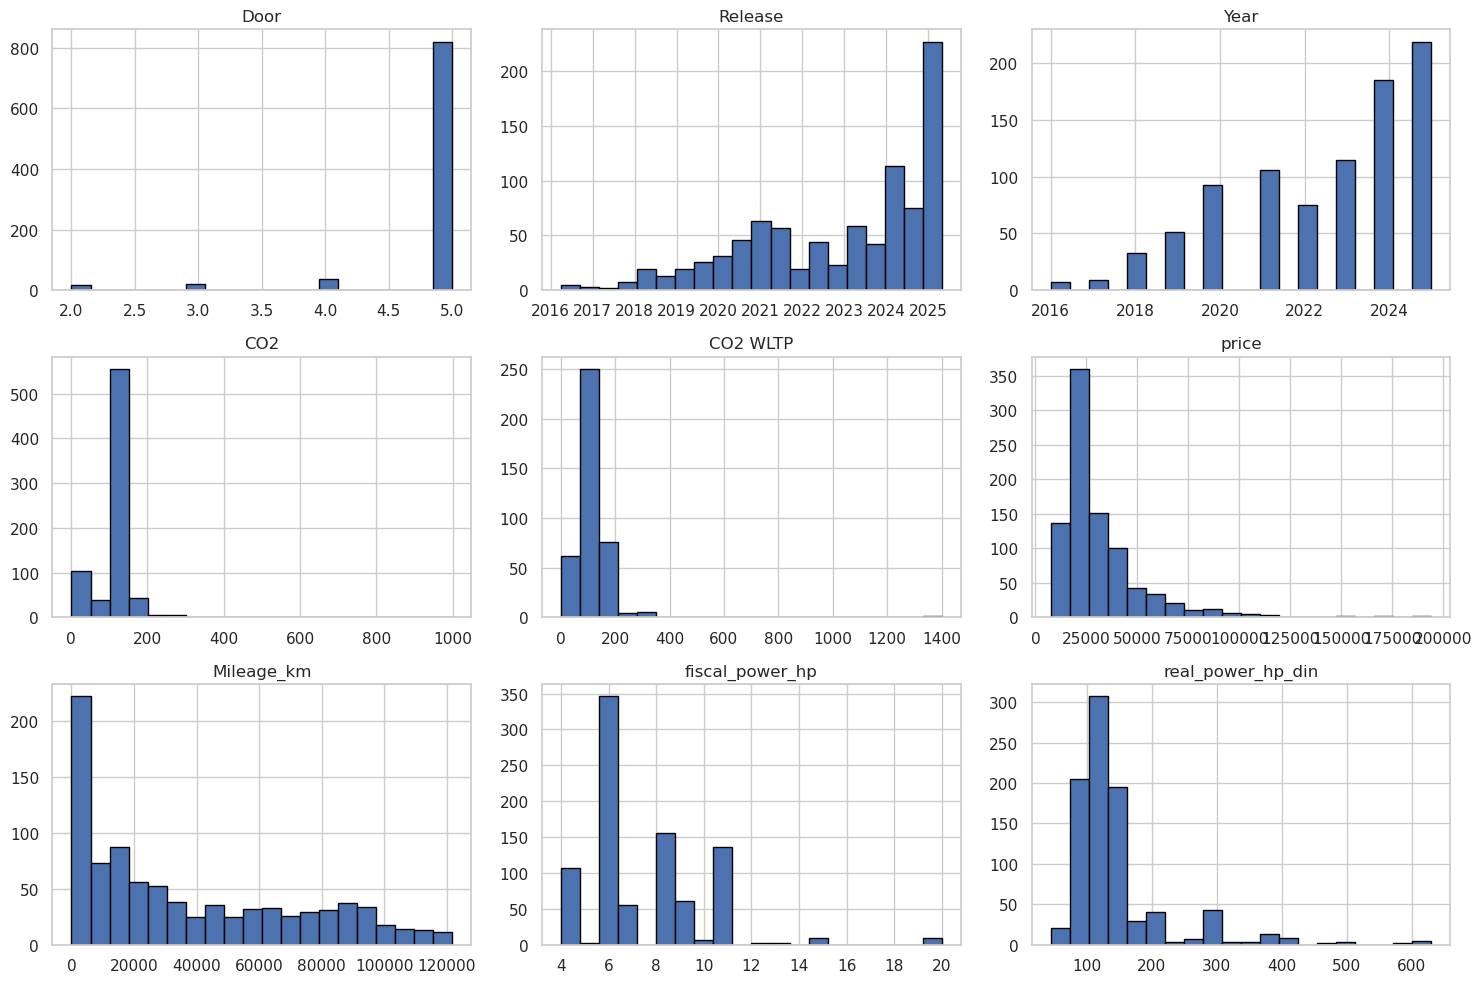

In [23]:
df.hist(bins=20, figsize=(15, 10), edgecolor='black')
plt.tight_layout()
plt.show()

In [ ]:
df[]

### Boxplots 

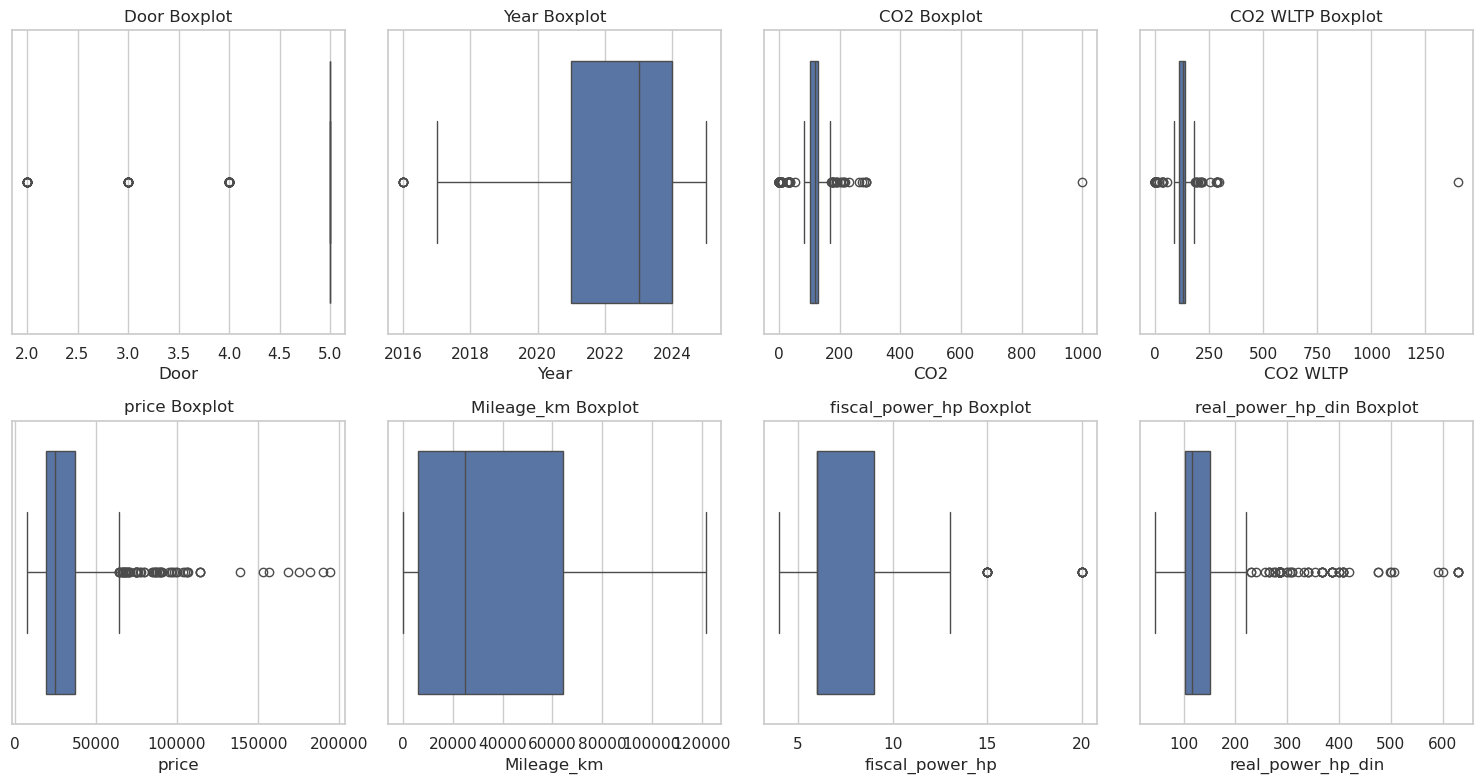

In [24]:
num_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(15, 8))
for i, col in enumerate(num_cols):
    plt.subplot(2, (len(num_cols) + 1) // 2, i + 1)
    sns.boxplot(data=df, x=col)
    plt.title(f'{col} Boxplot')
plt.tight_layout()
plt.show()

## Recoding equipments values

In [25]:
def equipments_to_list(x):
    if type(x) == str:
        return x[2:-2].replace("\'","").split(", ")
    return []


In [26]:
df["equipments"].apply(equipments_to_list)

0       [Air conditioning, Back electric windows, Back...
1       [16" wheels, Aloy wheels, Android Auto, Apple ...
2       [Aloy wheels, Android Auto, Apple CarPlay, Arm...
3       [Alarm, Aloy wheels, Android Auto, Apple CarPl...
4       [16" wheels, Air conditioning, Android Auto, A...
                              ...                        
1219    [All season tires, Aloy wheels, Ambient lighti...
1220    [16" wheels, Aloy wheels, Android Auto, Apple ...
1221    [19" wheels, Adaptive headlights, Aloy wheels,...
1222    [16" wheels, Aloy wheels, Android Auto, Apple ...
1229    [Aloy wheels, Android Auto, Apple CarPlay, Arm...
Name: equipments, Length: 893, dtype: object

In [27]:
equipments_df = df[["vehicle reference", "equipments"]]

In [28]:
equipments_df.set_index("vehicle reference", inplace=True)

In [32]:
equipments_df.dropna(inplace=True)
# equipments_df['equipments'] = equipments_df['equipments'].apply(ast.literal_eval)

/tmp/ipykernel_530/3289820179.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  equipments_df.dropna(inplace=True)


In [33]:
equipments_df['equipments'] = equipments_df['equipments'].apply(ast.literal_eval)

/tmp/ipykernel_530/1785723891.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  equipments_df['equipments'] = equipments_df['equipments'].apply(ast.literal_eval)


In [34]:
equipments_df

,equipments
vehicle reference,
FB118600,"[Air conditioning, Back electric windows, Back..."
FB118869,"[16"" wheels, Aloy wheels, Android Auto, Apple ..."
FB118871,"[Aloy wheels, Android Auto, Apple CarPlay, Arm..."
FB120521,"[Alarm, Aloy wheels, Android Auto, Apple CarPl..."
FB128840,"[16"" wheels, Air conditioning, Android Auto, A..."
...,...
FB112981,"[All season tires, Aloy wheels, Ambient lighti..."
FB118040,"[16"" wheels, Aloy wheels, Android Auto, Apple ..."
FB118044,"[19"" wheels, Adaptive headlights, Aloy wheels,..."


In [35]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
equipments_df = pd.DataFrame(mlb.fit_transform(equipments_df['equipments']),
                              columns=mlb.classes_,
                              index=equipments_df.index)

In [36]:
display(equipments_df)
equipments_df.to_csv("cars_with_equipments/equipments.csv")

,"15"" wheels","16"" wheels","18"" wheels","19"" wheels","20"" wheels","21"" wheels",360° caméea,7 seats,Adaptive headlights,Air conditioning,Air suspension,Alarm,All season tires,Aloy wheels,Ambient lighting,Android Auto,Apple CarPlay,Armrest,Automatic air conditioning,"Automatic climate control, 2 zones","Automatic climate control, 3 zones","Automatic climate control, 4 zones",Automatically dimming interior mirror,Auxiliary heating,Back electric windows,Back rear parking system,Blind spot monitor,Bluetooth,Central door lock,Cooling seats,Cruise control,Cruise/distance control,Daytime running lights,Digital cockpit,Digital radio,Driver drowsiness detection,Driver-side airbag,Driving assistance,ESP,Electric backseat adjustment,Electric front seat adjustment,Electric mirror,Electric tailgate,Electrically heated windshield,Electronic parking brake,Emergency brake assistant,Emergency system,Fog headlights,Front electric windows,Front rear parking system,GPS system,HIFI-System,Hands-free equipment,Head-up display,Headlight washer system,Heated front seats,Heated steering wheel,High beam assist,Hill Holder,Induction charging for smartphones,Isofix,Keyless central door lock,Kit winter tires,LED Daytime Running Lights,LED headlights,Lane departure warning system,Laser headlights,Leather steering wheel,Light sensors,Lumbar support,Massage seats,Multi-function steering wheel,Night view assist,On board computer,Opening roof,Panoramic roof,Park Assist,Passenger-side airbag,Power steering system,Radio/CD,Radio/MP3,Rain sensors,Range extender,Reserverad,Reverse camera,Roof rack,Shift paddles,Side airbag,Sliding door,Spoiler,Sport package,Sport seats,Sport suspension,Stability control,Start-stop system,Summer tires,Television,Tinted windows,Tire pressure monitoring system,Touch screen,Tow hook,Traction control,Traffic sign recognition,USB,Voice control,WLAN / WiFi hotspot,"Wheels 17""",Winter tires,Xenon headlights
vehicle reference,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
FB118600,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,0,1,0,0,0,1,0,1,0,1,0,0,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0,0
FB118869,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,1,1,0,1,1,0,1,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,1,0,0,0,0,0
FB118871,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,1,0,0,1,0,0,1,1,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,1,0,0,1,0,0,0,0,0,1,1,0,0,1,1,1,0,0,0,1,0,0,0,0,0
FB120521,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,1,1,1,0,0,0,1,0,1,1,0,1,1,0,1,1,0,0,1,0,1,0,1,0,0,1,0,0,1,1,1,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,1,0,0,1,0,1,0,0,0,1,1,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,1,1,0,0,1,0,0
FB128840,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,1,0,1,0,1,0,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,1,0,1,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FB112981,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,1,1,0,1,1,0,0,0,0,0,1,0,1,0,1,0,0,1,1,0,1,1,1,0,1,1,1,0,1,0,0,1,0,0,1,0,1,0,0,1,1,0,0,1,1,1,0,1,0,1,1,1,1,1,1,0,1,1,0,0,1,0,0,1,0,0,1,1,0,0,0,0,0,1,1,1,0,0,1,1,0,0,0,0,0
FB118040,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,1,0,0,1,0,1,1,0,1,1,0,1,0,0,1,1,1,1,1,1,0,0,1,0,0,0,1,1,1,1,1,1,0,1,0,0,1,0,0,0,0,1,0,0,0

OSError: Cannot save file into a non-existent directory: 'cars_with_equipments'

## Dealing with missing values

In [37]:
df.isnull().sum() / df.shape[0] * 100

Bodywork               0.000000
Color                  0.000000
Critair certifcate     1.903695
euro Norm              0.000000
Door                   0.000000
Fuel                   0.000000
Gearbox                0.000000
Model                  0.000000
Version                0.000000
Brand                  0.000000
Type                   0.000000
Release                0.000000
Year                   0.000000
Service book           0.000000
vehicle reference      0.000000
equipments             1.455767
CO2                   15.789474
CO2 WLTP              55.207167
price                  0.000000
Mileage_km             0.000000
fiscal_power_hp        0.000000
real_power_hp_din      0.000000
dtype: float64

In [38]:
df.set_index("vehicle reference", inplace=True)

In [39]:
# drop column equipments - it's saved in csv anyway
df.drop(["equipments"], axis=1, inplace=True)

<AxesSubplot:ylabel='vehicle reference'>

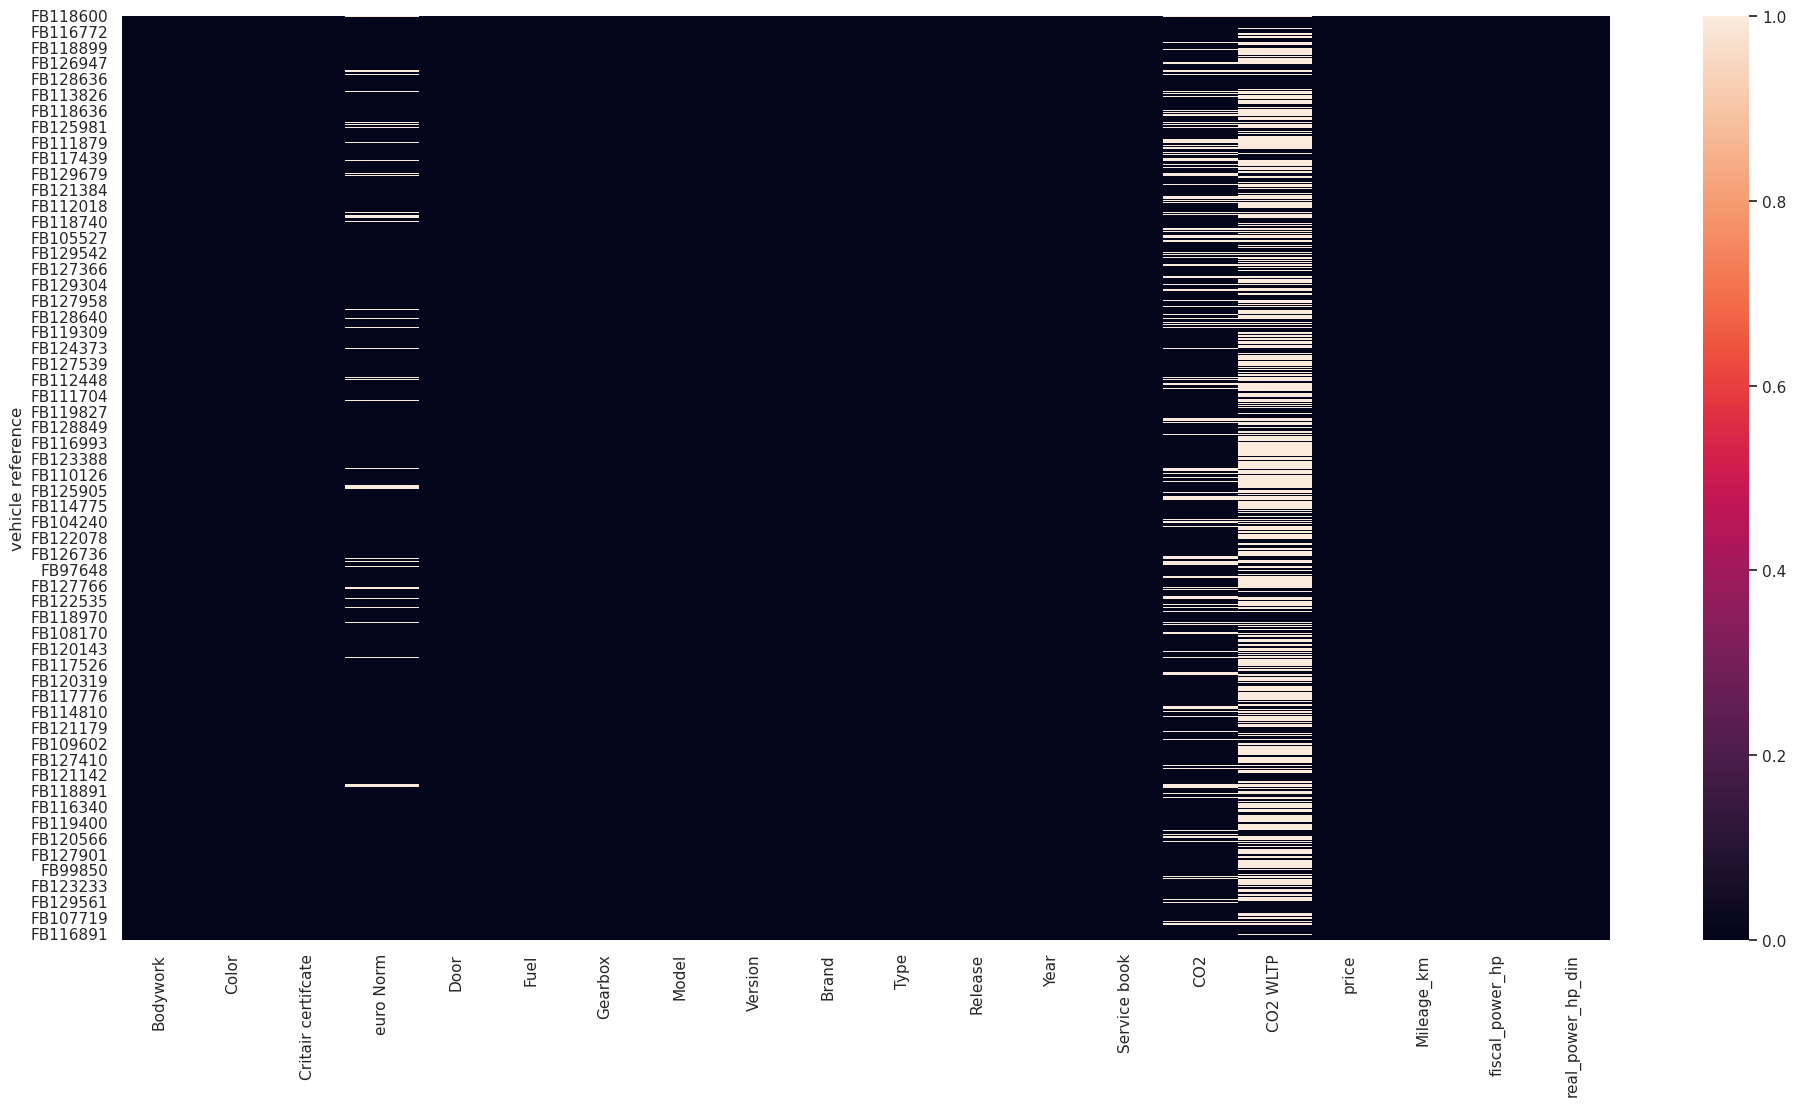

In [42]:
plt.figure(figsize=(24,12))
sns.heatmap(df.isna())

In [51]:
df.isnull().sum() / df.shape[0] * 100

Bodywork               0.000000
Color                  0.000000
Critair certifcate     0.000000
euro Norm              4.452055
Door                   0.000000
Fuel                   0.000000
Gearbox                0.000000
Model                  0.000000
Version                0.000000
Brand                  0.000000
Type                   0.000000
Release                0.000000
Year                   0.000000
Service book           0.000000
CO2                   16.095890
CO2 WLTP              55.479452
price                  0.000000
Mileage_km             0.000000
fiscal_power_hp        0.000000
real_power_hp_din      0.000000
dtype: float64

df.isnull().sum() / df.shape[0] * 100## Plot CO2 vs year

In [43]:
df[["Release", "Fuel", "Year", "CO2", "real_power_hp_din"]]

,Release,Fuel,Year,CO2,real_power_hp_din
vehicle reference,,,,,
FB118600,2021-10-12,Electric,2021,NaN,45
FB118869,2023-11-06,Gas,2023,114.0,91
FB118871,2023-09-14,Hybrid,2023,83.0,95
FB120521,2024-04-29,Gas,2024,130.0,91
FB128840,2020-01-16,Gas,2020,99.0,101
...,...,...,...,...,...
FB112981,2022-03-30,Gas,2022,154.0,136
FB118040,2025-04-30,Gas,2025,130.0,95
FB118044,2025-04-30,Gas,2025,127.0,150


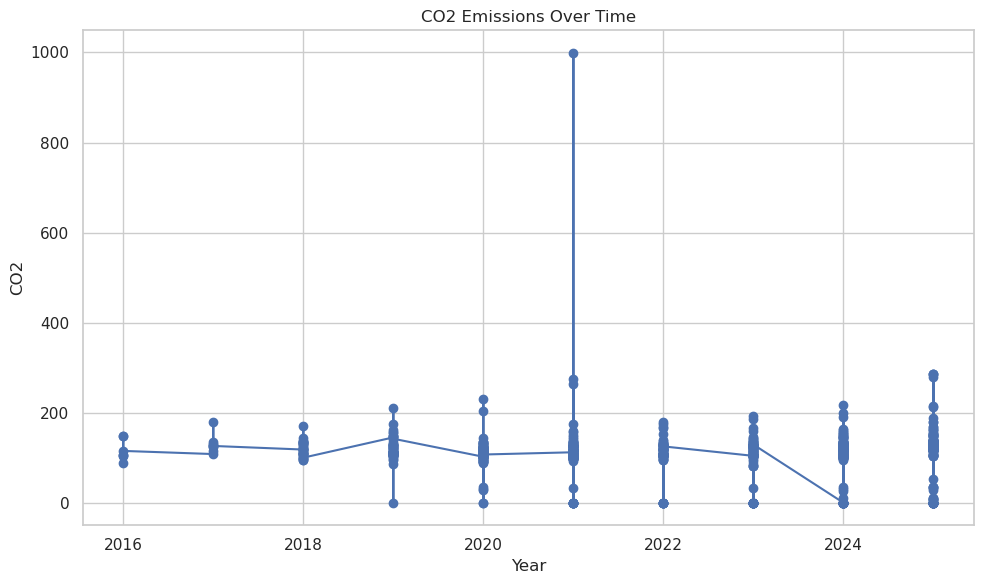

In [44]:
df_sorted = df[["Year", "CO2"]].sort_values(by='Year')

# Plot
plt.figure(figsize=(10, 6))
plt.plot(df_sorted['Year'], df_sorted['CO2'], marker='o')
plt.xlabel('Year')
plt.ylabel('CO2')
plt.title('CO2 Emissions Over Time')
plt.grid(True)
plt.tight_layout()
plt.show()


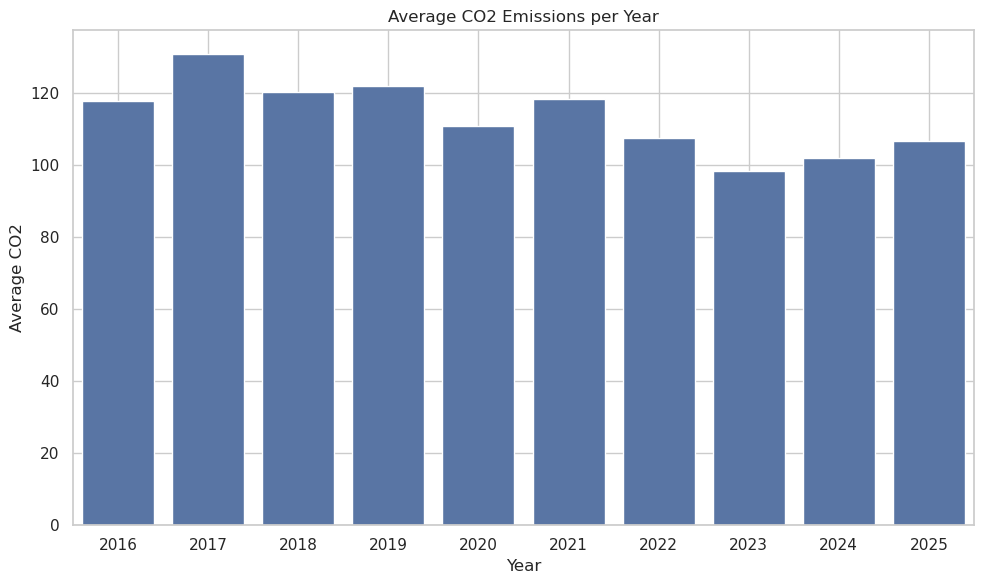

In [47]:
# Step 1: Group by year and calculate average CO2
df_grouped = df.groupby('Year', as_index=False)['CO2'].mean()

# Step 2: Sort by year (optional, but recommended)
df_grouped = df_grouped.sort_values('Year')

# Step 3: Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=df_grouped, x='Year', y='CO2')
plt.title('Average CO2 Emissions per Year')
plt.xlabel('Year')
plt.ylabel('Average CO2')
plt.grid(True)
plt.tight_layout()
plt.show()


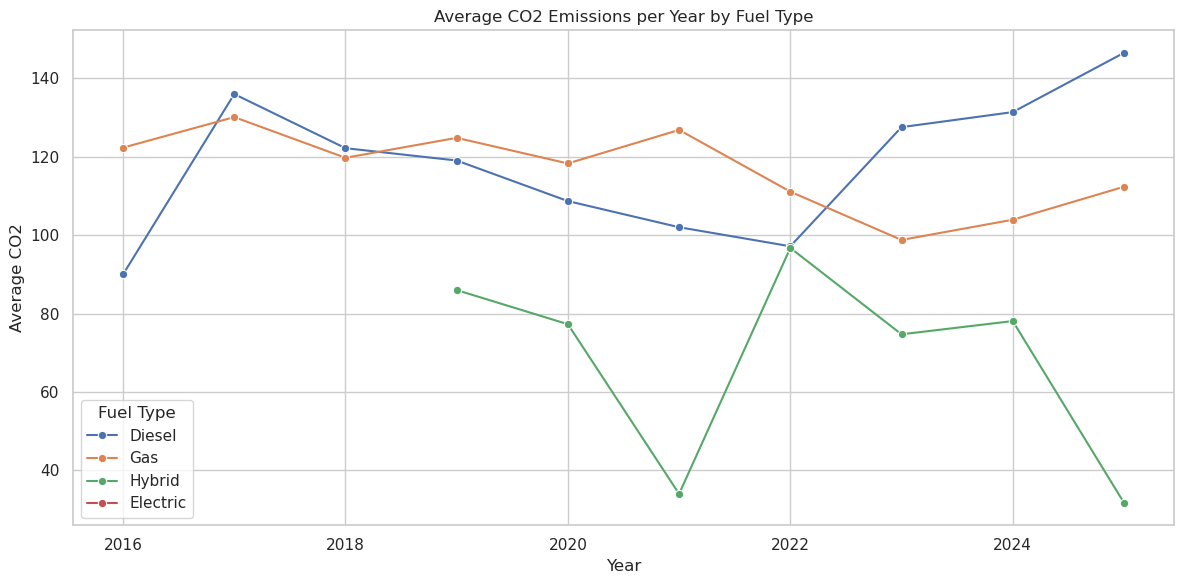

In [48]:
# Step 1: Group by Year and Fuel, then compute average CO2
df_grouped = df.groupby(['Year', 'Fuel'], as_index=False)['CO2'].mean()

# Step 2: Sort values by Year
df_grouped = df_grouped.sort_values('Year')

# Step 3: Plot with hue for Fuel type
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_grouped, x='Year', y='CO2', hue='Fuel', marker='o')
plt.title('Average CO2 Emissions per Year by Fuel Type')
plt.xlabel('Year')
plt.ylabel('Average CO2')
plt.grid(True)
plt.tight_layout()
plt.legend(title='Fuel Type')
plt.show()


In [49]:
df_grouped = df.groupby(["Type","Fuel"], as_index=False)['CO2'].mean()
df_grouped



,Type,Fuel,CO2
0,Demo,Diesel,144.937500
1,Demo,Electric,NaN
2,Demo,Gas,115.500000
3,Demo,Hybrid,45.315789
4,New,Diesel,141.375000
5,New,Electric,NaN
6,New,Gas,114.141026
7,New,Hybrid,39.181818
8,Second hand,Diesel,109.832000
9,Second hand,Electric,NaN


In [ ]:
df[(df["Fuel"] == "Electric")]

In [ ]:
df.isna().sum()

In [ ]:
df[(df["CO2"].isna() ) & (df["Fuel"] != "Electric")]

Text(0.5, 1.0, 'Fuel type histogram')

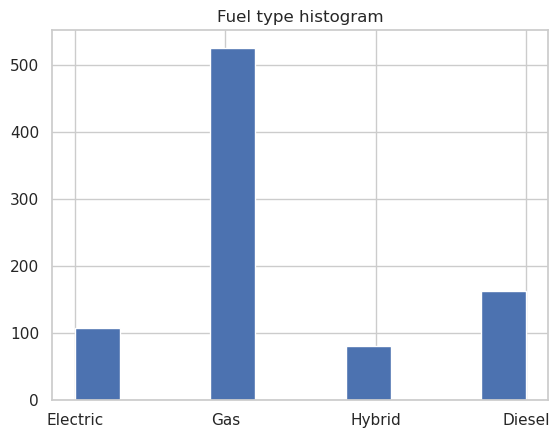

In [54]:
df["Fuel"].hist()
plt.title("Fuel type histogram")

In [53]:
df[df["Fuel"] == "Electric"]["CO2"].isna().sum()

107

In [82]:
df.shape

(876, 20)

## Regression model

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

### Model with only numerical values

In [175]:
numeric_features = ['Year', 'Mileage_km', 'real_power_hp_din', 'CO2']
target = 'price'
df_model = df[numeric_features + [target]].dropna()
print(df_model.shape)

X = df_model[numeric_features]
y = df_model[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
reg_model = LinearRegression()
reg_model.fit(X_train, y_train)
y_pred = reg_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(mae, r2)

(752, 5)
4992.821641653641 0.8499907501922233


### Model with numerical and categorical values

In [178]:
categorical_features = ['Bodywork', 'Color', 'Fuel', 'Gearbox', 'Model']
numeric_features = ['Year', 'Mileage_km', 'real_power_hp_din', 'CO2']
target = 'price'

# Usunięcie wierszy z brakującymi danymi w wybranych kolumnach
df_model = df[categorical_features + numeric_features + [target]].dropna()

In [179]:
df_model.shape

(752, 10)

In [180]:
# Podział na cechy (X) i etykietę (y)
X = df_model[features]
y = df_model[target]

# Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Kolumny kategoryczne i numeryczne
categorical_features = ['Bodywork', 'Color', 'Fuel', 'Gearbox', 'Model']
numeric_features = ['Year', 'Mileage_km', 'real_power_hp_din']

# Przekształcenie danych kategorycznych
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'  # pozostawia kolumny numeryczne bez zmian
)

In [181]:
# Pipeline z przetwarzaniem danych i modelem regresji
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Trenowanie modelu
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Bodywork', 'Color', 'Fuel',
                                                   'Gearbox', 'Model'])])),
                ('regressor', LinearRegression())])

In [182]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(mae, r2)

4971.6943980000715 0.8642541858653218


### Regrssion with statsmodel

In [12]:
import pandas as pd
import numpy as np
from sklearn import datasets, linear_model
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy import stats
import statsmodels.formula.api as smf

numeric_features = ['Year', 'Mileage_km', 'real_power_hp_din', 'CO2']
target = 'price'
df_model = df[numeric_features + [target]].dropna()
print(df_model.shape)
X = df_model[numeric_features]
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X = df_model[numeric_features]
y = df_model[target]


X2 = sm.add_constant(X_train)
est = sm.OLS(y_train, X2)
est2 = est.fit()

print(est2.summary())

KeyError: "['CO2'] not in index"

In [255]:
X3 = sm.add_constant(X_test)
y_predict = est2.predict(X3)
mae = mean_absolute_error(y_test, y_predict)
r2 = r2_score(y_test, y_pred)

print(mae, r2)

4992.821641653021 0.8642541858653218


In [256]:
est2.params

const               -4.262565e+06
Year                 2.107036e+03
Mileage_km          -6.188072e-02
real_power_hp_din    2.524170e+02
CO2                 -6.300944e+00
dtype: float64

In [230]:
X3.shape

(151, 5)

### C02 has high p-value, drop it

In [447]:
import pandas as pd
import numpy as np
from sklearn import datasets, linear_model
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy import stats

numeric_features = ['Year', 'Mileage_km', 'real_power_hp_din']
target = 'price'
df_model = df[numeric_features + [target]].dropna()
print(df_model.shape)
X = df_model[numeric_features]
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X = df_model[numeric_features]
y = df_model[target]

X2 = sm.add_constant(X_train)
est = sm.OLS(y_train, X2)
est2 = est.fit()
print(est2.summary())
print(est2

(893, 4)
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.838
Model:                            OLS   Adj. R-squared:                  0.837
Method:                 Least Squares   F-statistic:                     1226.
Date:                Sun, 29 Jun 2025   Prob (F-statistic):          3.18e-280
Time:                        14:00:33   Log-Likelihood:                -7504.4
No. Observations:                 714   AIC:                         1.502e+04
Df Residuals:                     710   BIC:                         1.504e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const             -4.077e+06 

In [340]:
X4 = sm.add_constant(X_test)
y_predict = est2.predict(X4)
mae = mean_absolute_error(y_test, y_predict)
r2 = r2_score(y_test, y_predict)

print(mae, r2)

6565.308430276231 0.801390005495913


### statsmodel with one-hot encoding

In [347]:
import statsmodels.formula.api as smf

# categorical_features = ['Bodywork', 'Color', 'Fuel', 'Gearbox', 'Model', 'Type']
categorical_features = ['Bodywork', 'Fuel', 'Color']

numeric_features = ['Year', 'Mileage_km', 'real_power_hp_din']
all_car_models = df['Model'].unique()

target = 'price'
features = categorical_features + numeric_features
# Usunięcie wierszy z brakującymi danymi w wybranych kolumnach
df_model = df[features + [target]].dropna()

train, test = train_test_split(df_model, test_size=0.2, random_state=42)

est2 = smf.ols(formula="price ~ Year + Mileage_km + real_power_hp_din + C(Bodywork) + C(Fuel)", data=train).fit() 

#est2 = smf.ols(formula="price ~ Year + Mileage_km + real_power_hp_din + C(Type) + C(Model, levels=all_car_models) + C(Gearbox) + C(Fuel)", data=train).fit()
print(train.shape)
print(est2.summary())

(714, 7)
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.873
Model:                            OLS   Adj. R-squared:                  0.867
Method:                 Least Squares   F-statistic:                     151.2
Date:                Sat, 28 Jun 2025   Prob (F-statistic):          8.33e-282
Time:                        19:20:02   Log-Likelihood:                -7418.0
No. Observations:                 714   AIC:                         1.490e+04
Df Residuals:                     682   BIC:                         1.505e+04
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept      

In [345]:
y_predict = est2.predict(test[features], transform=True)
mae = mean_absolute_error(test['price'], y_predict)
r2 = r2_score(test['price'], y_predict)

print(mae, r2)

6466.999785794476 0.7983819471280167


In [361]:
df.isna().sum()

Bodywork                0
Color                   0
Critair certifcate     17
euro Norm              39
Door                    0
Fuel                    0
Gearbox                 0
Model                   0
Version                 0
Brand                   0
Type                    0
Release                 0
Year                    0
Service book            0
vehicle reference       0
equipments             13
CO2                   141
CO2 WLTP              493
price                   0
Mileage_km              0
fiscal_power_hp         0
real_power_hp_din       0
dtype: int64

In [323]:
df['Gearbox'].unique()

array(['Automatic', 'Manual'], dtype=object)

### Testing multiple formulas

In [387]:
formulas = ["price ~ Year + Mileage_km + real_power_hp_din", 
            "price ~ Year + Mileage_km + real_power_hp_din + Door",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox) + C(Bodywork)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Model, levels=all_car_models)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Model, levels=all_car_models) + C(Gearbox) + C(Bodywork)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Model, levels=all_car_models) + C(Gearbox) + C(Bodywork) + C(Color) "]
features = [
    'Bodywork', 'Color', 'Fuel', 'Gearbox', 'Model',
    'Year', 'Mileage_km', 'real_power_hp_din', 'Door'
]
all_car_models = df['Model'].unique()
df_model = df[features + [target]].dropna()
best_r2 = 0
best_formula = ""
best_model = None
for f in formulas:
    train, test = train_test_split(df_model, test_size=0.2, random_state=42)
    est2 = smf.ols(formula=f, data=train).fit() 
    y_predict = est2.predict(test[features], transform=True)
    mae = mean_absolute_error(test['price'], y_predict)
    r2 = r2_score(test['price'], y_predict)
    print("-----------------------------------------------------------------------------------")
    print(f)
    print(mae, r2)
    print(est2.summary())
    if r2 > best_r2:
        best_r2 = r2
        best_formula = f
        best_model = est2
print(f"BEST FORMULA: {best_formula}")

-----------------------------------------------------------------------------------
price ~ Year + Mileage_km + real_power_hp_din
6565.308430276234 0.801390005495913
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.838
Model:                            OLS   Adj. R-squared:                  0.837
Method:                 Least Squares   F-statistic:                     1226.
Date:                Sat, 28 Jun 2025   Prob (F-statistic):          3.18e-280
Time:                        20:12:04   Log-Likelihood:                -7504.4
No. Observations:                 714   AIC:                         1.502e+04
Df Residuals:                     710   BIC:                         1.504e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err     

### ignore model

In [3]:
df = pd.read_csv("../data/all_cars_cleaned2.csv")

In [15]:
formulas =['price ~ Year + Mileage_km + real_power_hp_din',
           'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Color) + C(Gearbox) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Bodywork) + C(Gearbox)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Gearbox)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Type)',
 'price ~ Year + Mileage_km + real_power_hp_din + Door']
formulas

['price ~ Year + Mileage_km + real_power_hp_din',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Color) + C(Gearbox) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Bodywork) + C(Gearbox)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Gearbox)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Type)',
 'price ~ Year + Mileage_km + real_power_hp_din + Door']

In [16]:
formulas = ['price ~ Year + Mileage_km + real_power_hp_din',
            'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel)',
            'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Bodywork)',
            'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Color, levels=all_colors) + C(Gearbox) + C(Bodywork)',
            'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox)',
            'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox) + C(Bodywork)',
            'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type)', 
            'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Bodywork)',
            'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Bodywork) + C(Gearbox)',
            'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Gearbox)',
            'price ~ Year + Mileage_km + real_power_hp_din + C(Type)',
            'price ~ Year + Mileage_km + real_power_hp_din + Door']

features = [
    'Bodywork', 'Color', 'Fuel', 'Gearbox', 'Type',
    'Year', 'Mileage_km', 'real_power_hp_din', 'Door'
]
target = 'price'
# all_car_models = df['Model'].unique()
all_colors = df['Color'].unique()
df_model = df[features + [target]].dropna()
best_r2 = 0
best_formula = ""
best_model = None
results = []
for f in formulas:
    train, test = train_test_split(df_model, test_size=0.2, random_state=42)
    est2 = smf.ols(formula=f, data=train).fit() 
    y_predict = est2.predict(test[features], transform=True)
    mae = mean_absolute_error(test['price'], y_predict)
    r2 = r2_score(test['price'], y_predict)
    print("-----------------------------------------------------------------------------------")
    print(f)
    print(mae, r2)
    print(est2.summary())
    results.append((f, r2, mae))
    if r2 > best_r2:
        best_r2 = r2
        best_formula = f
        best_model = est2
print(f"BEST FORMULA: {best_formula}")

-----------------------------------------------------------------------------------
price ~ Year + Mileage_km + real_power_hp_din
6316.740266258371 0.8529788679076975
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.825
Model:                            OLS   Adj. R-squared:                  0.825
Method:                 Least Squares   F-statistic:                     1108.
Date:                Sun, 29 Jun 2025   Prob (F-statistic):          3.88e-266
Time:                        14:29:01   Log-Likelihood:                -7466.9
No. Observations:                 708   AIC:                         1.494e+04
Df Residuals:                     704   BIC:                         1.496e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err    

In [469]:
!pip install --upgrade tabulate

In [470]:
import tabulate

In [18]:
results_df = pd.DataFrame(results, columns=['formula', 'r2', 'mae'])
print(results_df.to_markdown())

|    | formula                                                                                                          |       r2 |     mae |
|---:|:-----------------------------------------------------------------------------------------------------------------|---------:|--------:|
|  0 | price ~ Year + Mileage_km + real_power_hp_din                                                                    | 0.852979 | 6316.74 |
|  1 | price ~ Year + Mileage_km + real_power_hp_din + C(Fuel)                                                          | 0.861973 | 6025.7  |
|  2 | price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Bodywork)                                            | 0.858761 | 6121.86 |
|  3 | price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Color, levels=all_colors) + C(Gearbox) + C(Bodywork) | 0.856879 | 6124.15 |
|  4 | price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox)                                             | 0.864818 | 5884.22 |

In [19]:
print(df.describe().to_markdown())

|       |       Year |   Mileage_km |   real_power_hp_din |       Door |    price |
|:------|-----------:|-------------:|--------------------:|-----------:|---------:|
| count |  885       |        885   |            885      | 885        |    885   |
| mean  | 2022.55    |      36837.4 |            147.181  |   4.8565   |  31817.1 |
| std   |    2.23945 |      34829.4 |             81.6757 |   0.536849 |  22572.7 |
| min   | 2016       |          0   |             45      |   2        |   7490   |
| 25%   | 2021       |       6152   |            102      |   5        |  18990   |
| 50%   | 2023       |      25000   |            116      |   5        |  24990   |
| 75%   | 2024       |      63881   |            150      |   5        |  36990   |
| max   | 2025       |     121747   |            630      |   5        | 194310   |


In [462]:
results_df.

,formula,r2,mae
0,price ~ Year + Mileage_km + real_power_hp_din ...,0.858341,5922.329103
1,price ~ Year + Mileage_km + real_power_hp_din ...,0.854257,5804.726834
2,price ~ Year + Mileage_km + real_power_hp_din ...,0.863075,5780.935153
3,price ~ Year + Mileage_km + real_power_hp_din ...,0.876183,5498.100071
4,price ~ Year + Mileage_km + real_power_hp_din ...,0.872499,5594.252994
5,price ~ Year + Mileage_km + real_power_hp_din ...,0.855578,5936.686531
6,price ~ Year + Mileage_km + real_power_hp_din ...,0.873943,5555.311210
7,price ~ Year + Mileage_km + real_power_hp_din ...,0.859776,5899.654588
8,price ~ Year + Mileage_km + real_power_hp_din,0.843745,6054.146968
9,price ~ Year + Mileage_km + real_power_hp_din ...,0.878170,5423.906758


In [370]:
df[categorical_features].count()

Bodywork    893
Fuel        893
Color       893
dtype: int64

In [376]:
max(df.groupby("Model")["Model"].count())

42

In [377]:
df.groupby("Bodywork")["Bodywork"].count()

Bodywork
Break        117
Cabriolet     13
Coupé         49
Monospace     37
Other          4
SAV            1
SUV          361
Sedan        154
Urban        137
Utility       20
Name: Bodywork, dtype: int64

In [378]:
df.groupby("Color")["Color"].count()

Color
Anthracite      60
Beige            1
Black          193
Blue           110
Bronze           2
Brown            2
Champagne        2
Green           10
Grey           284
Not defined      3
Orange           6
Red             30
Silver          62
White          123
Yellow           5
Name: Color, dtype: int64

In [381]:
df.groupby("Type")["Type"].count()

Type
Demo           165
New            167
Second hand    561
Name: Type, dtype: int64

In [398]:
df.groupby("Fuel")["Fuel"].count()

Fuel
Diesel      163
Electric    107
Gas         526
Hybrid       80
LPG          16
Other         1
Name: Fuel, dtype: int64

<AxesSubplot:ylabel='Fuel'>

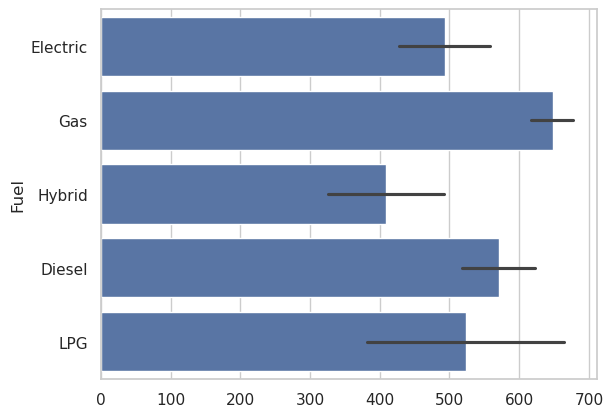

In [445]:
sns.barplot(df["Fuel"])

In [399]:
df.groupby("Bodywork")["Bodywork"].count()

Bodywork
Break        117
Cabriolet     13
Coupé         49
Monospace     37
Other          4
SAV            1
SUV          361
Sedan        154
Urban        137
Utility       20
Name: Bodywork, dtype: int64

In [20]:
df.shape

(885, 11)

In [403]:
tmp = ["price ~ Year + Mileage_km + real_power_hp_din", 
            "price ~ Year + Mileage_km + real_power_hp_din + Door",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Type)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox) + C(Bodywork)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Bodywork)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Color) + C(Gearbox) + C(Bodywork)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Gearbox)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Bodywork)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Bodywork) + C(Gearbox)"
            ] + ["price ~ Year + Mileage_km + real_power_hp_din", 
            "price ~ Year + Mileage_km + real_power_hp_din + Door",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox) + C(Bodywork)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Model, levels=all_car_models)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Model, levels=all_car_models) + C(Gearbox) + C(Bodywork)",
            "price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Model, levels=all_car_models) + C(Gearbox) + C(Bodywork) + C(Color) "]
set(tmp)

{'price ~ Year + Mileage_km + real_power_hp_din',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Color) + C(Gearbox) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Gearbox) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Model, levels=all_car_models)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Model, levels=all_car_models) + C(Gearbox) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Model, levels=all_car_models) + C(Gearbox) + C(Bodywork) + C(Color) ',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel) + C(Type) + C(Bodywork)',
 'price ~ Year + Mileage_km + real_power_hp_din + C(Fuel

In [407]:
df2 = pd.read_csv("../data/all_cars.csv")
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1231 entries, 0 to 1230
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Bodywork                  1231 non-null   object 
 1   Color                     1231 non-null   object 
 2   Mixed consumption         1231 non-null   object 
 3   Critair certifcate        1205 non-null   object 
 4   euro Norm                 1231 non-null   object 
 5   Door                      1231 non-null   object 
 6   Fuel                      1231 non-null   object 
 7   Gearbox                   1231 non-null   object 
 8   Fiscal power              1231 non-null   object 
 9   Real power                1231 non-null   object 
 10  Model                     1231 non-null   object 
 11  Version                   1231 non-null   object 
 12  Mileage                   1231 non-null   object 
 13  Brand                     1231 non-null   object 
 14  Price al

In [408]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 893 entries, 0 to 1229
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Bodywork            889 non-null    object        
 1   Color               893 non-null    object        
 2   Critair certifcate  876 non-null    object        
 3   euro Norm           854 non-null    object        
 4   Door                893 non-null    int64         
 5   Fuel                892 non-null    object        
 6   Gearbox             893 non-null    object        
 7   Model               893 non-null    object        
 8   Version             893 non-null    object        
 9   Brand               893 non-null    object        
 10  Type                893 non-null    object        
 11  Release             893 non-null    datetime64[ns]
 12  Year                893 non-null    int64         
 13  Service book        893 non-null    object        
 14

In [413]:
df["Brand"].unique()

array(['Dacia', 'Renault', 'Peugeot', 'SsangYong', 'Toyota', 'Opel',
       'Nissan', 'Suzuki', 'Kia', 'Lexus', 'Seat', 'Ford', 'Tesla',
       'Fiat', 'Volkswagen', 'Audi', 'Skoda', 'Cupra', 'MINI',
       'Mercedes-Benz', 'Porsche', 'Alfa Romeo', 'Mitsubishi', 'BMW',
       'Jaguar', 'Hyundai', 'Volvo', 'Citroen', 'Jeep', 'Land Rover'],
      dtype=object)

In [416]:
df.groupby("Brand")["Brand"].count()

Brand
Alfa Romeo         2
Audi             219
BMW               18
Citroen            2
Cupra             28
Dacia             40
Fiat               7
Ford              13
Hyundai            8
Jaguar             1
Jeep               1
Kia               14
Land Rover         1
Lexus              2
MINI               5
Mercedes-Benz      6
Mitsubishi         2
Nissan             3
Opel               4
Peugeot           12
Porsche            4
Renault          127
Seat              39
Skoda            103
SsangYong          2
Suzuki             4
Tesla              1
Toyota             5
Volkswagen       218
Volvo              2
Name: Brand, dtype: int64

In [436]:
df["Version"].nunique()

748

In [431]:
df.groupby("Critair certifcate")["Critair certifcate"].count()

Critair certifcate
level 0    107
level 1    606
level 2    163
Name: Critair certifcate, dtype: int64

In [432]:
df.groupby("euro Norm")["euro Norm"].count()

euro Norm
Euro 6    849
Euro 7      5
Name: euro Norm, dtype: int64

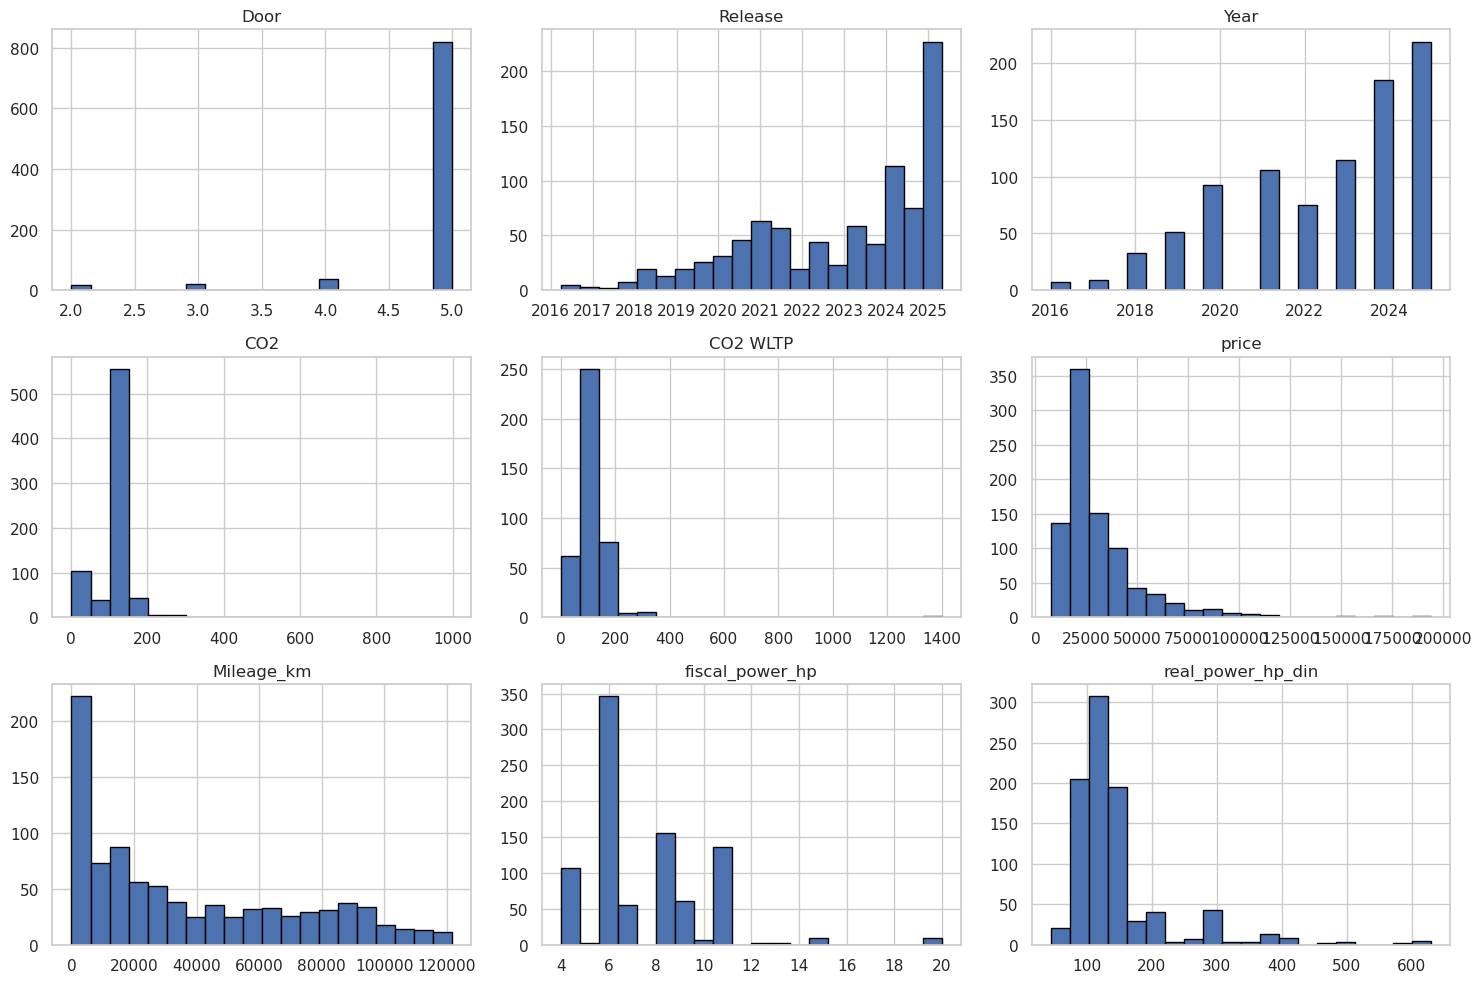

In [437]:
df.hist(bins=20, figsize=(15, 10), edgecolor='black')
plt.tight_layout()
plt.show()

<AxesSubplot:ylabel='Color'>

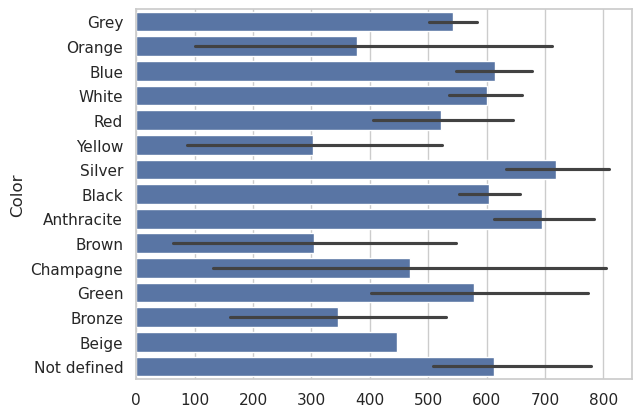

In [446]:
sns.barplot(df["Color"])